<a href="https://colab.research.google.com/github/MariaVrett/Bayes/blob/main/Bayes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Import Libraries

In [74]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import re
import string
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, classification_report

# Load Dataset and Split

In [75]:
df = pd.read_csv('train.csv')

# Train-Test Split (90-10%) using stratify
train_df, test_df = train_test_split(df, test_size=0.10, random_state=0, stratify=df['target'])

# Bar Plots

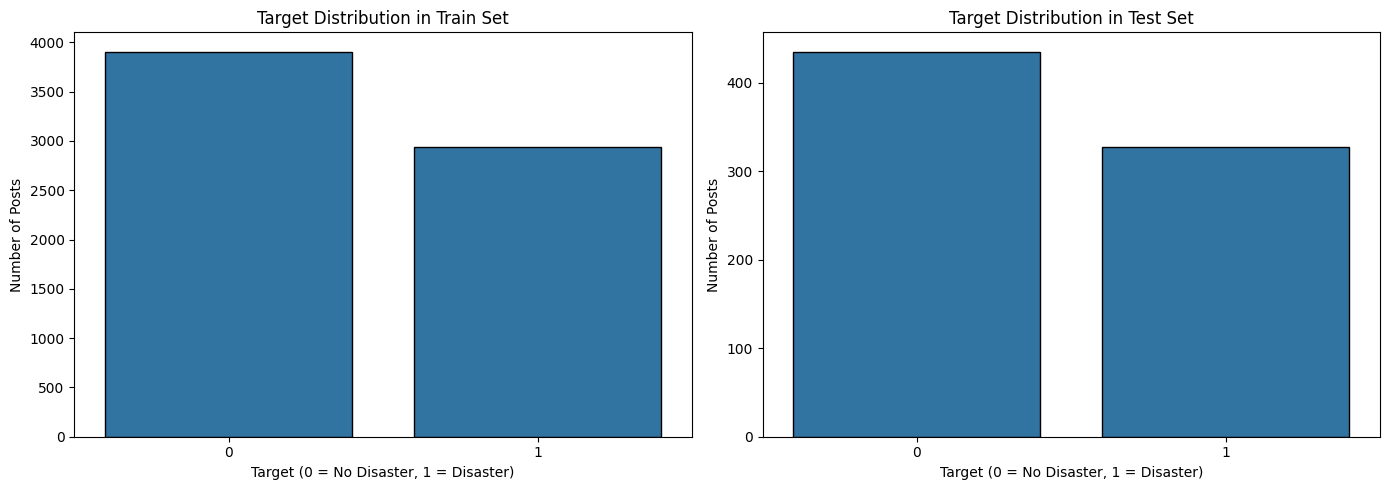

In [76]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(data=train_df, x='target', ax=axes[0], edgecolor='black')
axes[0].set_title('Target Distribution in Train Set')
axes[0].set_xlabel('Target (0 = No Disaster, 1 = Disaster)')
axes[0].set_ylabel('Number of Posts')

sns.countplot(data=test_df, x='target', ax=axes[1], edgecolor='black')
axes[1].set_title('Target Distribution in Test Set')
axes[1].set_xlabel('Target (0 = No Disaster, 1 = Disaster)')
axes[1].set_ylabel('Number of Posts')

plt.tight_layout()
plt.show()

# Check For Class Imbalance

In [77]:
print("Class Distribution Percentages (Target):")
print(df['target'].value_counts(normalize=True) * 100)


Class Distribution Percentages (Target):
target
0    57.034021
1    42.965979
Name: proportion, dtype: float64


Class Imbalance Commentary:** The dataset presents a slight imbalance, as the negative class (target=0) accounts for ~57% of the data, while the positive class (target=1) accounts for ~43%. Although it is not perfectly balanced (50-50), the difference is minor and usually does not require extreme balancing techniques (like SMOTE).

# Data Preprocessing

In [78]:
# Removing 'id' and location features
# Fill missing values (NaN) with the keyword "null"
# Merge keyword and text columns
def preprocess_data(data):
    df_temp = data.copy()
    df_temp = df_temp.drop(columns=['id', 'location'], errors='ignore')
    df_temp = df_temp.fillna("null")
    df_temp['inputs'] = df_temp['keyword'].astype(str) + ' ' + df_temp['text'].astype(str)
    return df_temp

train_df = preprocess_data(train_df)
test_df = preprocess_data(test_df)

# Text Cleaning

In [79]:
def removeUnicode(text):
    """ Removes unicode strings like "\u002c" and "x96" """
    text = re.sub(r'(\\u[0-9A-Fa-f]+)',r'', text)
    text = re.sub(r'[^\x00-\x7f]',r'',text)
    return text

def replaceURL(text):
    """ Replaces url address with "url" """
    text = re.sub(r'((www\.[^\s]+)|(https?://[^\s]+))','url',text)
    text = re.sub(r'#([^\s]+)', r'\1', text)
    return text

def replaceAtUser(text):
    """ Replaces "@user" with "atUser" """
    text = re.sub(r'@[^\s]+','atUser',text)
    return text

def removeNumbers(text):
    """ Removes integers """
    text = ''.join([i for i in text if not i.isdigit()])
    return text

def removeEmoticons(text):
    """ Removes emoticons from text """
    text = re.sub(r':\)|;\)|:-\)|\(-:|:-D|=D|:P|xD|X-p|\^\^|:-*|\^\.\^|\^\-\^|\^\_\^|\,-\)|\)-:|:\'\(|:\(|:-\(|:\S|T\.T|\.\_\.|:<|:-\S|:-<|\*\-\*|:O|=O|=\-O|O\.o|XO|O\_O|:-\@|=/|:/|X\-\(|>\.<|>=\(|D:', '', text)
    return text

def clean_text(text):
    text = removeUnicode(text)
    text = replaceURL(text)
    text = replaceAtUser(text)
    text = removeEmoticons(text)
    text = removeNumbers(text)

    # Final step: Lowercase and remove punctuation for optimal TF-IDF tokenization
    text = text.lower().translate(str.maketrans('', '', string.punctuation))
    text = re.sub(r'\s+', ' ', text).strip()
    return text

# Apply the cleaning function
train_df['inputs'] = train_df['inputs'].apply(clean_text)
test_df['inputs'] = test_df['inputs'].apply(clean_text)

Description and Justification of Cleaning Techniques:
*   **removeUnicode:** Removes non-ASCII characters to eliminate garbled text and irrelevant symbols from the dataset.
*   **replaceURL:** Replaces web links with a generic 'url' token, as specific URLs do not generalize well for classification.
*   **replaceAtUser:** Replaces Twitter handles with 'atUser' to group all user mentions together and reduce vocabulary sparsity.
*   **removeEmoticons:** Strips emoticons, which generally act as noise when trying to detect factual disaster information.
*   **removeNumbers**: Deletes digits, helping the model focus strictly on semantic words rather than arbitrary dates or values.

# Split into Inputs and Targets (Numpy Arrays)

In [80]:
x_train_text = train_df['inputs'].to_numpy()
y_train = train_df['target'].to_numpy()

x_test_text = test_df['inputs'].to_numpy()
y_test = test_df['target'].to_numpy()

print(f"Train arrays - X: {x_train_text.shape}, Y: {y_train.shape}")
print(f"Test arrays  - X: {x_test_text.shape}, Y: {y_test.shape}")

Train arrays - X: (6851,), Y: (6851,)
Test arrays  - X: (762,), Y: (762,)


# Convert Texts with TF-IDF Vectorizer

In [81]:
tfidf = TfidfVectorizer(max_features=5000)

# fit_transform on train set and only transform on test set
x_train_tfidf = tfidf.fit_transform(x_train_text)
x_test_tfidf = tfidf.transform(x_test_text)

x_train_dense = x_train_tfidf.toarray()
x_test_dense = x_test_tfidf.toarray()

# Train Gaussian Naive Bayes Classifier

In [82]:
gnb = GaussianNB()
gnb.fit(x_train_dense, y_train)
y_pred = gnb.predict(x_test_dense)

# Evaluate the model
print("Gaussian Naive Bayes Test Set Results")
print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred))

Gaussian Naive Bayes Test Set Results
Accuracy: 0.6286

Classification Report:
              precision    recall  f1-score   support

           0       0.81      0.46      0.59       435
           1       0.54      0.85      0.66       327

    accuracy                           0.63       762
   macro avg       0.67      0.66      0.62       762
weighted avg       0.69      0.63      0.62       762

